In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y número de operarios necesarios por actividad se adjunta. Todas las actividades se han programado en su inicio más temprano.

In [4]:
pregunta_1 = "1. Dibuje el diagrama de Gantt y el diagrama de cargas. ¿Cuál es el número máximo de operarios necesario y en qué semanas?  "
pregunta_2 = "2. ¿Está nivelado el consumo de recursos? Calcule la suma de cuadrados de las cargas como medida de desnivel.  "
pregunta_3 = "3. Nivele los recursos desplazando actividades no críticas dentro de su holgura, sin alargar el proyecto, con el algoritmo de mínimos cuadrados. Indique qué actividades desplaza y cuánto.  "
pregunta_4 = "4. Compare el diagrama de cargas antes y después: máximo de operarios y suma de cuadrados.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el diagrama de Gantt y el diagrama de cargas. ¿Cuál es el número máximo de operarios necesario y en qué semanas?  

2. ¿Está nivelado el consumo de recursos? Calcule la suma de cuadrados de las cargas como medida de desnivel.  

3. Nivele los recursos desplazando actividades no críticas dentro de su holgura, sin alargar el proyecto, con el algoritmo de mínimos cuadrados. Indique qué actividades desplaza y cuánto.  

4. Compare el diagrama de cargas antes y después: máximo de operarios y suma de cuadrados.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 4       , 4        ),
    ('B'     , '---'      , 3       , 4        ),
    ('C'     , '---'      , 2       , 2        ),
    ('D'     , 'A,B,C'    , 3       , 4        ),
    ('E'     , 'C'        , 4       , 1        ),
    ('F'     , 'E'        , 1       , 1        ),
    ('G'     , 'E'        , 2       , 1        ),
    ('H'     , 'D,G'      , 1       , 3        ),
    ('I'     , 'F,H'      , 1       , 1        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,4,4
B,---,3,4
C,---,2,2
D,"A,B,C",3,4
E,C,4,1
F,E,1,1
G,E,2,1
H,"D,G",1,3
I,"F,H",1,1


El proyecto corresponde a la rehabilitación de una nave industrial para un taller; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Levantamiento topográfico y mediciones',
    'B': 'Proyecto de ejecución y licencia',
    'C': 'Desmontaje de instalaciones antiguas',
    'D': 'Demolición de tabiquería interior',
    'E': 'Refuerzo de la estructura metálica',
    'F': 'Reparación de la cubierta',
    'G': 'Solera y canalizaciones',
    'H': 'Cerramientos y carpintería exterior',
    'I': 'Instalación eléctrica',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Levantamiento topográfico y mediciones
B,Proyecto de ejecución y licencia
C,Desmontaje de instalaciones antiguas
D,Demolición de tabiquería interior
E,Refuerzo de la estructura metálica
F,Reparación de la cubierta
G,Solera y canalizaciones
H,Cerramientos y carpintería exterior
I,Instalación eléctrica


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Dibuje el diagrama de Gantt y el diagrama de cargas. ¿Cuál es el número máximo de operarios necesario y en qué semanas?  

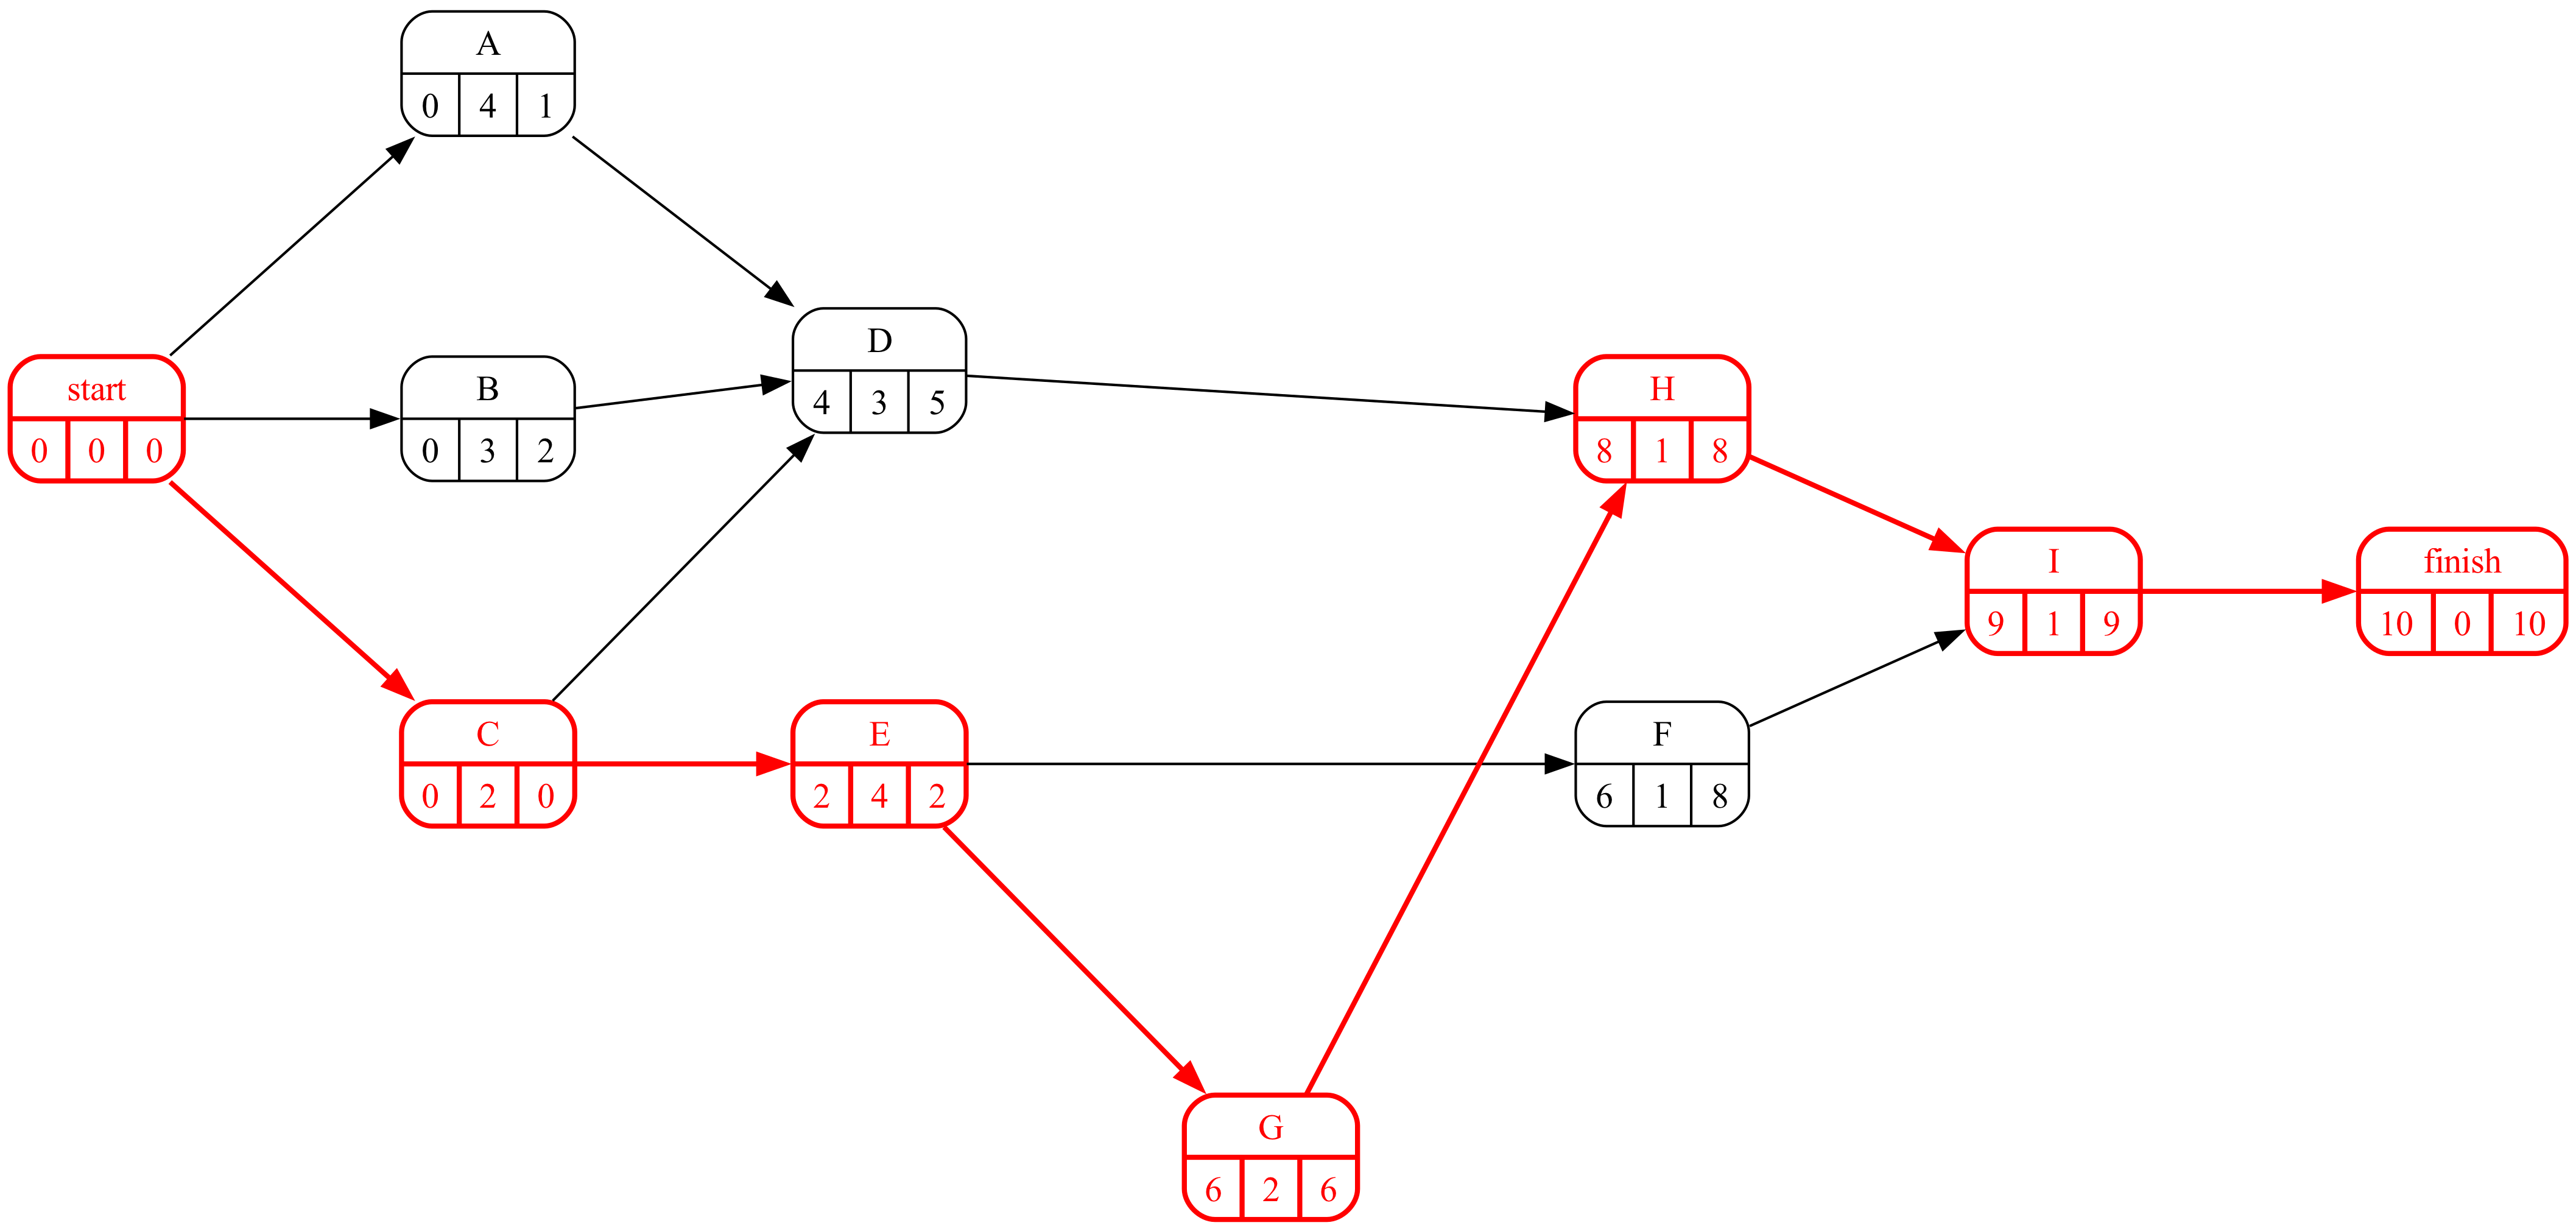

In [9]:
#| fig-cap: "Grafo Roy con tiempos y camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

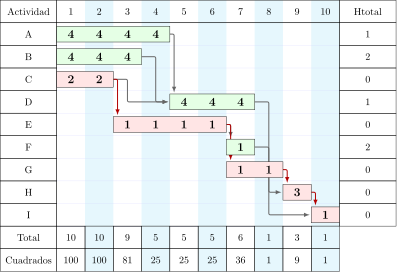

In [10]:
#| fig-cap: "Diagrama de Gantt con las cargas de operarios (inicios más tempranos)"
#| label: fig-ganttInicial
proyecto_inicial = proyecto.copy()
gantt_inicial, dibujo = proyecto_inicial.gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

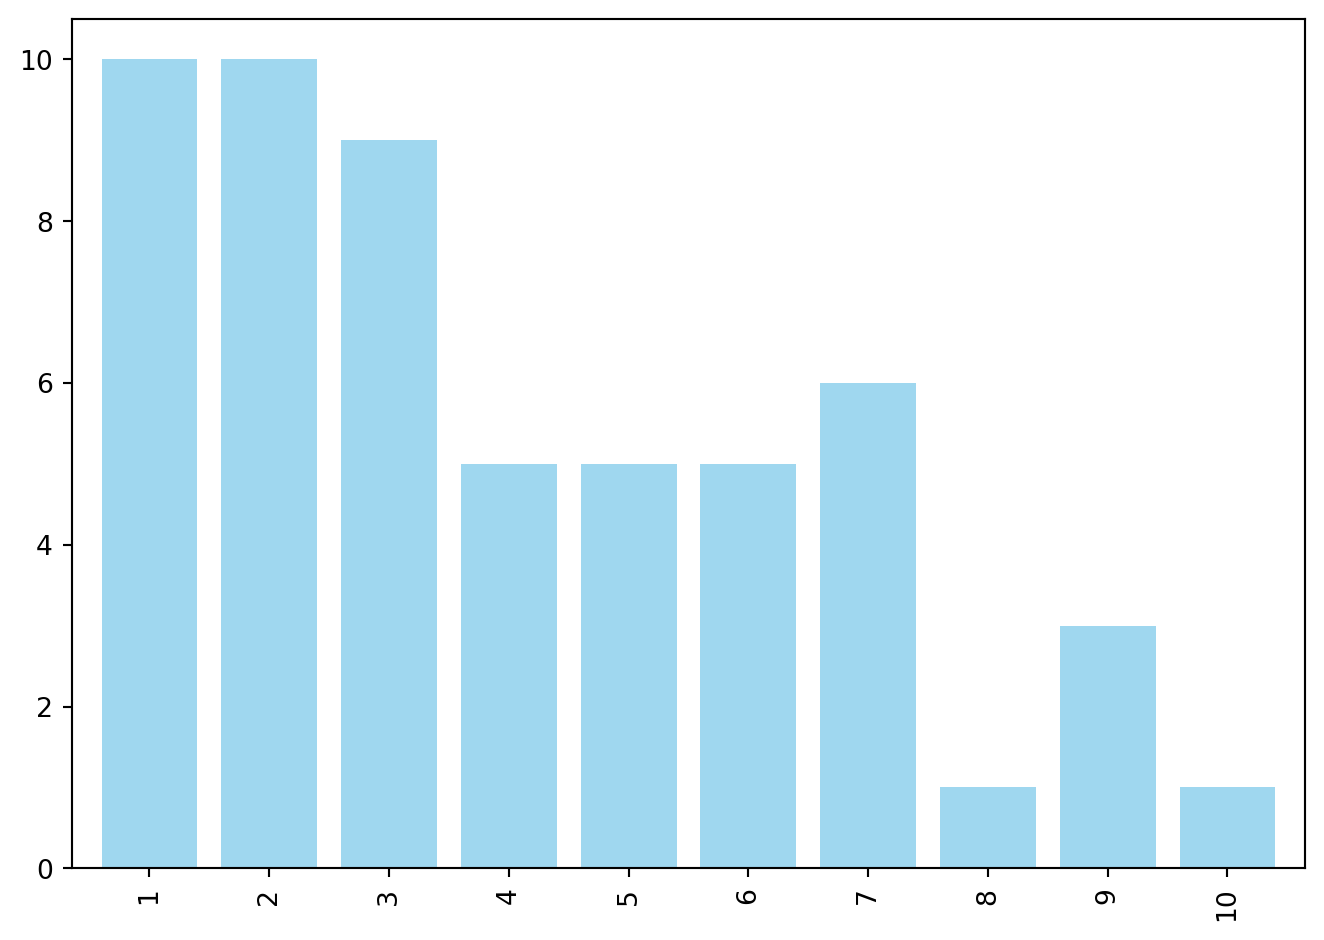

In [11]:
#| fig-cap: "Diagrama de cargas de operarios"
#| label: fig-cargasInicial
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=None)

In [12]:
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
semanas_pico = cargas.index[cargas == cargas.max()].tolist()
Markdown(f'El máximo de operarios es {int(cargas.max())}, en las semanas {", ".join(map(str, semanas_pico))}. '
         f'La media es {cargas.mean():.2f} operarios/semana.')

El máximo de operarios es 10, en las semanas 1, 2. La media es 5.50 operarios/semana.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. ¿Está nivelado el consumo de recursos? Calcule la suma de cuadrados de las cargas como medida de desnivel.  

La suma de cuadrados de las cargas, $\sum_t c_t^2$, penaliza los picos: para una misma carga total es mínima cuando el perfil es plano. Es la función objetivo de la nivelación.

In [14]:
suma_cuadrados_inicial = float((cargas ** 2).sum())
Markdown(f'Suma de cuadrados inicial: {suma_cuadrados_inicial:.0f}. La carga total es {cargas.sum():.0f} operarios·semana; '
         f'si se repartiera uniformemente en {len(cargas)} semanas la suma de cuadrados sería {len(cargas) * cargas.mean() ** 2:.0f}.')

Suma de cuadrados inicial: 403. La carga total es 55 operarios·semana; si se repartiera uniformemente en 10 semanas la suma de cuadrados sería 302.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. Nivele los recursos desplazando actividades no críticas dentro de su holgura, sin alargar el proyecto, con el algoritmo de mínimos cuadrados. Indique qué actividades desplaza y cuánto.  

El algoritmo recorre las actividades no críticas (por orden de fin más temprano) y, para cada una, prueba todos los desplazamientos dentro de su holgura eligiendo el que minimiza la suma de cuadrados. La tabla muestra la suma de cuadrados para cada desplazamiento posible, con el mínimo resaltado.

In [16]:
#| tbl-cap: "Suma de cuadrados para cada desplazamiento posible"
#| label: tbl-cuadrados
proyecto_nivelado = proyecto.copy()
desplazamientos, cuadrados, datos_nivelados, gantt_nivelado, dibujo = proyecto_nivelado.nivelar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources')
cuadrados

,0,1,2
activity,,,
B,403,395,355
A,355,379,
F,355,355,351
D,351,,


In [17]:
#| tbl-cap: "Desplazamientos elegidos"
#| label: tbl-desplazamientos
desplazamientos[desplazamientos['desplazamientos'] > 0]

,desplazamientos
B,2
F,2


## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Compare el diagrama de cargas antes y después: máximo de operarios y suma de cuadrados.  

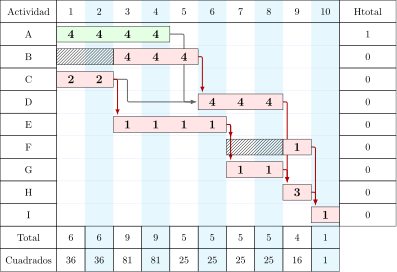

In [19]:
#| fig-cap: "Diagrama de Gantt tras la nivelación"
#| label: fig-ganttNivelado
gantt_nivelado, dibujo = proyecto_nivelado.gantt_cargas(datos_nivelados, 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

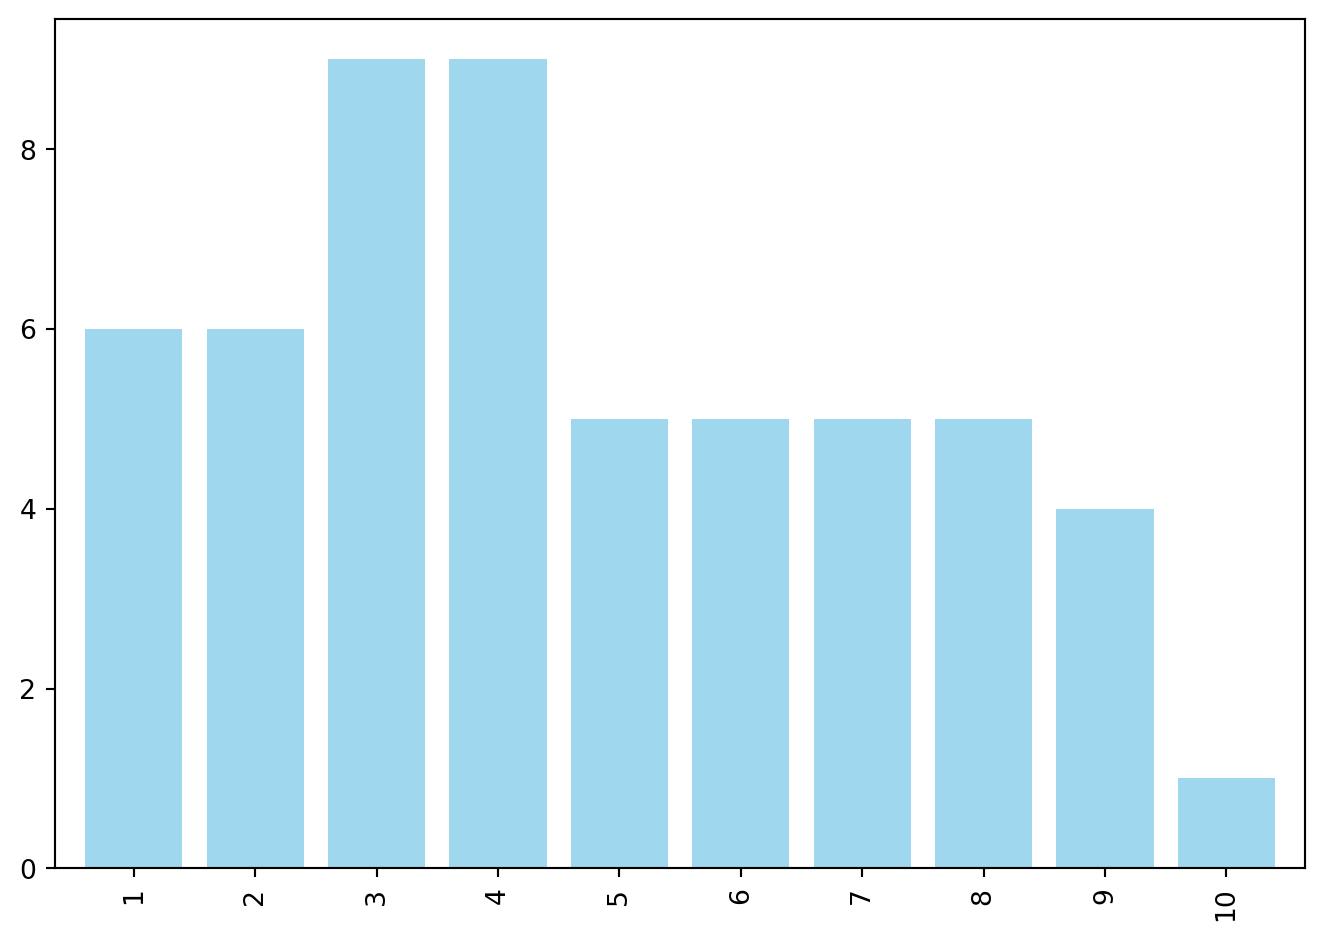

In [20]:
#| fig-cap: "Diagrama de cargas tras la nivelación"
#| label: fig-cargasNivelado
plot_cargas(gantt_df=gantt_nivelado, limite_maximo_recursos=None)

In [21]:
cargas_niveladas = gantt_nivelado.data.loc['Total'].drop('H_total').astype(float)
pd.DataFrame({'antes': [cargas.max(), (cargas ** 2).sum(), len(cargas)],
              'después': [cargas_niveladas.max(), (cargas_niveladas ** 2).sum(), len(cargas_niveladas)]},
             index=['máximo de operarios', 'suma de cuadrados', 'duración']).astype(int)

,antes,después
máximo de operarios,10,9
suma de cuadrados,403,351
duración,10,10


La duración no cambia porque sólo se han movido actividades dentro de su holgura; el perfil es más plano y el máximo de operarios, menor o igual.